# Project 1

Welcome to the first NLP1 project. The goal of the first tutorial was to get you familiar with text segmentation and simple text classification for topic detection.
Given the skills you have developed in the first week, you will now be applying them within a different dataset and task.

We are recommending a set of tasks and associated datasets; using those, you will be experimenting on problems introduced during the tutorials. You will be applying hands-on the experiments you have already explored in the last tutorial, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and analysing errors. 

The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

As the tutorials will be building upon your knowledge throughout the weeks, the task and dataset you choose now will be the ones you use in projects 2 and 3; and the ones you will be finally writing about in your final blog post.  

## Get to work!

The next section has a checklist to help you not lose track of what needs to be done. Here we have a more informal guide, with prompts and questions for you. 


1. [Choose a dataset](http://nlp-illc.github.io/nlp1/). Spend some time understanding how the dataset looks and some statistics of it (e.g. how many instances of each classification label we have?)
2. Remember what we learnt during the tutorial: to develop any classifier of the kind we saw, we needed a way to segment text. Do you want to use the tokeniser we have developed? Do you need to train a new one? If you do, what hyperparameters shall you use? What data shall you use to train it? Consider that your dataset may be too small to train a tokeniser! Think whether you will need a larger resource of similar nature to train a tokeniser.
3. Start thinking how to represent your documents into features. We have experimented with token occurences and frequencies. Can you think of any other ways, possibly? 
4. We had experimented with Logistic Regression and a shallow neural network. You can experiment with and assess different architectures now and their hyper parameters (e.g. add layers, possibly change the activation functions, drop out rates).
5. Evaluate your models! Was the evaluation method adequate for your new experimental setup? Do you want to assess other aspects of performance?
6. Analyse the various models you assessed and try to decide on which is the best.

Be mindful that you will be using your experiments to write up your final blog, so make sure they are clean and neat!

You can write your own code and you can reuse code from the tutorial and its packages or from other sources. You may use coding assistants if you like, but use it mindfully as you take full responsibility for this kind of (semi-)automated coding. Also, keep a record of the kinds of things you delegate to any form of assistant, as you will be asked to disclose this in your blog post (not because we will pass a value judgement on it, but because it is a widespread and good practice to document such things).

You may use jupyter notebooks or python files, it's up to you as we will not directly assess your code. But, once again, be organised, as we will ask you to share a reproducible version of your experiments along with your blog post (again, because this is how real research is publicised). 

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

## Checklist

What **we expect you to do**:

- [ ] Compare different systems of text classification for your choice of data/task.
- Your comparisons should cover:
    - [ ] the two representation spaces in the tutorial (token indicators and bag-of-words) and an additional one of your choice.
    - [ ] the two kinds of architectures in the tutorial (log-linear and single-hidden-layer MLP) and an additional one of your choice (such as a modification of the MLP).
- [ ] Your comparisons must be based on cross-validation and a relevant metric (accuracy or else).
- [ ] You should make use of Bayesian estimation to help you analyse results in relation to a region of practical equivalence (ROPE), and you can motivate the ROPE size yourself.

What you need to **bring to the oral assessment**:
* You will be asked questions about the points above, you can bring a slide deck with up to six slides (one for each of the topics/questions in the 'Get to work!' section); you _will not_ give a presentation, rather, these slides are to be thought of as "backup slides" that you can use to guide your answers to the questions the TA will ask you.
* You may also be asked questions about the tutorial, for those, you don't need to prepare any deliverable (a good way to prepare is to work through the tutorial and reflect on the questions there).

What you should **keep in mind** given that you will eventually write a blog post about your work throughout the course:
* Organise your code;
* Summarise your motivations and findings;
* Document your sources and any form of AI-assistance you use.

# Start

In [2]:
# imports
from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

import re
from collections import Counter
from pathlib import Path

from IPython.display import display

pd.set_option("display.max_colwidth", None)

### Plotting settings

In [3]:
# plotting settings
LABELS = ["entailment", "neutral", "contradiction"]
LABEL_COLORS = {
    "entailment": "#2a78d6",
    "neutral": "#eb6834",
    "contradiction": "#1baf7a",
}

# some global style settings so that all plots look the same
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 10
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e6e5e1"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlelocation"] = "left"
plt.rcParams["legend.frameon"] = False

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

def save_figure(fig, name):
    fig.savefig(FIG_DIR / f"eda_{name}.png", dpi=200, bbox_inches="tight")

## EDA

In [4]:
# Multi-Genre Natural Language Inference (MultiNLI)

ds = load_dataset("nyu-mll/multi_nli")

# we put all three splits into one dataframe, with a column that says which split a row comes from
split_names = {
    "train": "train",
    "validation_matched": "dev matched",
    "validation_mismatched": "dev mismatched",
}
split_order = list(split_names.values())
columns = ["promptID", "pairID", "premise", "hypothesis", "genre", "label"]

frames = []
for hf_split, name in split_names.items():
    split_df = ds[hf_split].to_pandas()[columns]
    split_df["split"] = name
    frames.append(split_df)
df = pd.concat(frames, ignore_index=True)

# the label is stored as 0/1/2, so we also add the readable name
df["label_name"] = df["label"].map({0: "entailment", 1: "neutral", 2: "contradiction"})
df.head(3)

,promptID,pairID,premise,hypothesis,genre,label,split,label_name
0,31193,31193n,Conceptually cream skimming has two basic dimensions - product and geography.,Product and geography are what make cream skimming work.,government,1,train,neutral
1,101457,101457e,you know during the season and i guess at at your level uh you lose them to the next level if if they decide to recall the the parent team the Braves decide to call to recall a guy from triple A then a double A guy goes up to replace him and a single A guy goes up to replace him,You lose the things to the following level if the people recall.,telephone,0,train,entailment
2,134793,134793e,One of our number will carry out your instructions minutely.,A member of my team will execute your orders with immense precision.,fiction,0,train,entailment


In [5]:
# some basic numbers per split
rows = []
for split in split_order:
    part = df[df["split"] == split]
    rows.append({
        "split": split,
        "pairs": len(part),
        "unique premises": part["premise"].nunique(),
        "genres": part["genre"].nunique(),
        "no gold label (-1)": (part["label"] == -1).sum(),
        "empty premise": (part["premise"].str.strip() == "").sum(),
        "empty hypothesis": (part["hypothesis"].str.strip() == "").sum(),
        "duplicate pairs": part.duplicated(["premise", "hypothesis"]).sum(),
    })

pd.DataFrame(rows).set_index("split")

,pairs,unique premises,genres,no gold label (-1),empty premise,empty hypothesis,duplicate pairs
split,,,,,,,
train,392702,128144,5,0,0,0,125
dev matched,9815,3334,5,0,0,0,0
dev mismatched,9832,3335,5,0,0,0,2


The number of unique premises is 1/3 of the total amount of pairs in the dataset. This is because three annotators were shown one premise and asked to write one hypothesis per label

### Label Distribution

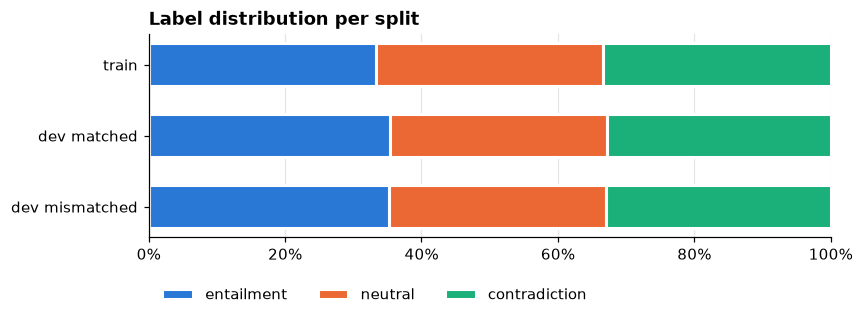

label_name,entailment,neutral,contradiction
split,,,
train,130899,130900,130903
dev matched,3479,3123,3213
dev mismatched,3463,3129,3240


label_name,entailment,neutral,contradiction
split,,,
train,33.3,33.3,33.3
dev matched,35.4,31.8,32.7
dev mismatched,35.2,31.8,33.0


In [6]:
# count how often each label occurs per split, and convert to percentages
label_counts = pd.crosstab(df["split"], df["label_name"])
label_counts = label_counts.loc[split_order, LABELS]
label_percentages = label_counts.div(label_counts.sum(axis=1), axis=0)

# stacked horizontal bar chart with one bar per split
fig, ax = plt.subplots(figsize=(8, 2.4))
left = np.zeros(len(split_order))
for label in LABELS:
    ax.barh(split_order, label_percentages[label], left=left, height=0.6,
            color=LABEL_COLORS[label], edgecolor="white", linewidth=2, label=label)
    left = left + label_percentages[label].values

ax.invert_yaxis()  # train on top
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Label distribution per split")
ax.legend(ncol=3, loc="upper left", bbox_to_anchor=(0, -0.18))
save_figure(fig, "label_balance")
plt.show()

display(label_counts)
display((label_percentages * 100).round(1))

### Genres

In [7]:
# number of examples per genre in each split
# (the dev mismatched genres don't appear in train, so we sort by train first and then by dev mismatched)
genre_counts = pd.crosstab(df["genre"], df["split"])
genre_counts = genre_counts[split_order]
genre_counts = genre_counts.sort_values(["train", "dev mismatched"], ascending=False)
display(genre_counts)

# label percentages per genre
genre_labels = pd.crosstab(df["genre"], df["label_name"], normalize="index")
genre_labels = genre_labels.loc[genre_counts.index, LABELS]
display((genre_labels * 100).round(1))

split,train,dev matched,dev mismatched
genre,,,
telephone,83348,1966,0
government,77350,1945,0
travel,77350,1976,0
fiction,77348,1973,0
slate,77306,1955,0
letters,0,0,1977
facetoface,0,0,1974
nineeleven,0,0,1974
oup,0,0,1961


label_name,entailment,neutral,contradiction
genre,,,
telephone,33.4,33.3,33.3
government,33.4,33.3,33.3
travel,33.4,33.3,33.3
fiction,33.4,33.3,33.3
slate,33.4,33.3,33.3
letters,37.4,29.6,33.0
facetoface,34.4,32.3,33.3
nineeleven,35.4,31.6,33.0
oup,35.0,32.7,32.3


### Easy Tokenizer to check composition per label

In [8]:
# simple tokenizer: lowercase the text and split it into words and punctuation.
# "n't" is split off as its own token, so "don't" becomes ["do", "n't"]
TOKEN_PATTERN = re.compile(r"\w+(?=n't)|n't|\w+|[^\w\s]")

def tokenize(text):
    return TOKEN_PATTERN.findall(text.lower())

df["premise_tokens"] = df["premise"].apply(tokenize)
df["hypothesis_tokens"] = df["hypothesis"].apply(tokenize)
df["premise_len"] = df["premise_tokens"].apply(len)
df["hypothesis_len"] = df["hypothesis_tokens"].apply(len)

# sentence length statistics (in tokens) per split
length_stats = df.groupby("split")[["premise_len", "hypothesis_len"]].describe()
length_stats.loc[split_order].T.round(1)

split                    train  dev matched  dev mismatched
premise_len    count  392702.0       9815.0          9832.0
               mean       23.2         22.6            23.3
               std        16.0         15.9            15.1
               min         1.0          1.0             3.0
               25%        12.0         12.0            13.0
               50%        20.0         19.0            20.0
               75%        30.0         30.0            30.0
               max       415.0        208.0           151.0
hypothesis_len count  392702.0       9815.0          9832.0
               mean       11.5         11.5            12.4
               std         4.7          4.7             5.0
               min         1.0          1.0             2.0
               25%         8.0          8.0             9.0
               50%        11.0         11.0            12.0
               75%        14.0         14.0            15.0
               max        71.0         51.0            68.0

### Negation words

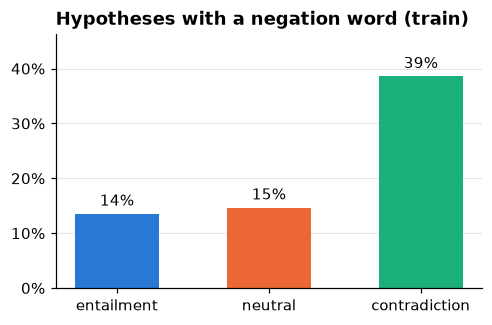

negation words: cannot, n't, neither, never, no, nobody, none, nor, not, nothing, nowhere


In [9]:
NEGATION_WORDS = {"not", "n't", "no", "never", "nobody", "nothing", "none", "nowhere", "neither", "nor", "cannot"}

def has_negation(tokens):
    return any(token in NEGATION_WORDS for token in tokens)

df["hyp_has_negation"] = df["hypothesis_tokens"].apply(has_negation)
train = df[df["split"] == "train"]

# percentage of hypotheses with a negation word, per label (train only)
negation_rate = train.groupby("label_name")["hyp_has_negation"].mean()
negation_rate = negation_rate[LABELS]

fig, ax = plt.subplots(figsize=(5, 3))
colors = [LABEL_COLORS[label] for label in LABELS]
bars = ax.bar(LABELS, negation_rate, color=colors, width=0.55)
ax.bar_label(bars, labels=[f"{rate:.0%}" for rate in negation_rate], padding=3)
ax.set_title("Hypotheses with a negation word (train)")
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylim(0, negation_rate.max() * 1.2)  # leave some room for the labels above the bars
ax.grid(axis="x", visible=False)
save_figure(fig, "negation_by_label")
plt.show()

print("negation words:", ", ".join(sorted(NEGATION_WORDS)))

### Most label-specific hypothesis words

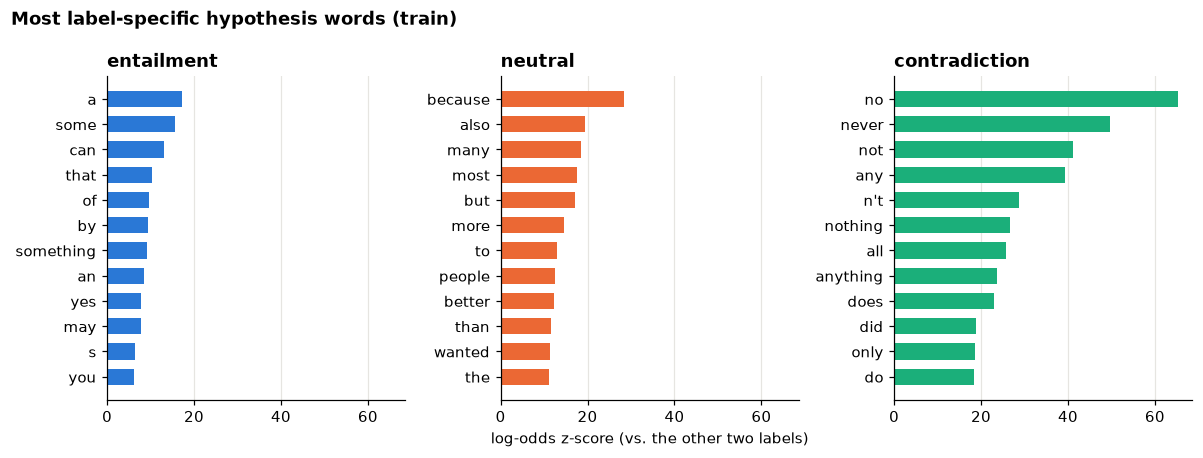

In [10]:
# Which hypothesis words are typical for one label compared to the other two?
# We use the log-odds ratio with an informative Dirichlet prior (Monroe et al., 2008).
# A high z-score means the word appears a lot more often for that label.

def log_odds_z_scores(counts_a, counts_b, prior, min_count=50):
    total_a = sum(counts_a.values())
    total_b = sum(counts_b.values())
    total_prior = sum(prior.values())

    scores = {}
    for word, prior_count in prior.items():
        # skip rare words and tokens without letters (punctuation, numbers)
        if prior_count < min_count or not re.search("[a-z]", word):
            continue

        a = counts_a[word] + prior_count
        b = counts_b[word] + prior_count
        log_odds_a = np.log(a / (total_a + total_prior - a))
        log_odds_b = np.log(b / (total_b + total_prior - b))
        variance = 1 / a + 1 / b
        scores[word] = (log_odds_a - log_odds_b) / np.sqrt(variance)

    return pd.Series(scores).sort_values(ascending=False)


# count the hypothesis words for each label
word_counts = {}
for label in LABELS:
    counter = Counter()
    for tokens in train.loc[train["label_name"] == label, "hypothesis_tokens"]:
        counter.update(tokens)
    word_counts[label] = counter

all_word_counts = word_counts["entailment"] + word_counts["neutral"] + word_counts["contradiction"]

# compare each label against the other two labels combined
z_scores = {}
for label in LABELS:
    other_counts = all_word_counts - word_counts[label]
    z_scores[label] = log_odds_z_scores(word_counts[label], other_counts, all_word_counts)

# plot the top 12 words per label
fig, axes = plt.subplots(1, 3, figsize=(11, 4.2), sharex=True)
for ax, label in zip(axes, LABELS):
    top_words = z_scores[label].head(12)
    top_words = top_words[::-1]  # reverse, so the highest score is at the top
    ax.barh(top_words.index, top_words.values, color=LABEL_COLORS[label], height=0.65)
    ax.set_title(label)
    ax.grid(axis="y", visible=False)

axes[1].set_xlabel("log-odds z-score (vs. the other two labels)")
fig.suptitle("Most label-specific hypothesis words (train)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_figure(fig, "label_words")
plt.show()

## Tokenizer

Can we reuse the tutorial's BPE tokenizer, or do we need to train a new one? The tutorial tokenizer was trained on AG News (news articles) with only 1,000 tokens, while MNLI is a mix of telephone conversations, fiction, government reports, travel guides and magazine articles.

We compare four BPE tokenizers. Each one changes **one thing** compared to the one above it, so we can see which choice matters:

| name | trained on | vocab size | normalisation / pre-tokenization |
|---|---|---|---|
| `tutorial` | AG News | 1,000 | none / Metaspace (exactly the tutorial tokenizer) |
| `agnews-10k` | AG News | 10,000 | none / Metaspace |
| `mnli-10k` | MNLI train | 10,000 | none / Metaspace |
| `mnli-10k-custom` | MNLI train | 10,000 | lowercase / Metaspace + split off punctuation and *n't* |

We evaluate them in two ways:
1. **Intrinsic**: how they segment held-out text (tokens per word, unknown tokens, how negation is represented). No classifier and no labels needed.
2. **Extrinsic**: cross-validated accuracy of the same simple classifier (logistic regression on bag-of-words) with each tokenizer. This is what matters in the end.

In [11]:
# imports
# reload our own modules (part1.nli etc.) automatically when they change, without restarting the kernel
%load_ext autoreload
%autoreload 2

import sys
sys.path.insert(0, str(Path.cwd().parent))  # so that "import part1" works from inside part1/ (as in the tutorial)

from scipy.sparse import hstack
from tokenizers import Tokenizer, Regex, normalizers, pre_tokenizers
from sklearn.linear_model import LogisticRegression

import part1.experiment
import part1.analysis
import part1.smlp
import part1.nli

In [12]:
# training corpora for the tokenizers
# in MNLI every premise appears ~3 times (once per hypothesis), so we use each premise only once
mnli_train = df[df["split"] == "train"]
mnli_corpus = list(mnli_train["premise"].unique()) + list(mnli_train["hypothesis"])
agnews_corpus = list(part1.experiment.download_ag_news_texts())

# custom pre-tokenizer: after Metaspace, split off punctuation and "n't"
# so "doesn't," becomes ["▁does", "n't", ","] instead of one token "▁doesn't,"
custom_pretokenizer = pre_tokenizers.Sequence([
    pre_tokenizers.Metaspace(),
    pre_tokenizers.Split(Regex(r"n't|[^\w\s▁]"), behavior="isolated"),
])

TOKENIZER_CONFIGS = {
    "tutorial": dict(corpus=agnews_corpus, vocab_size=1_000),
    "agnews-10k": dict(corpus=agnews_corpus, vocab_size=10_000),
    "mnli-10k": dict(corpus=mnli_corpus, vocab_size=10_000),
    "mnli-10k-custom": dict(corpus=mnli_corpus, vocab_size=10_000,
                            pretokenizer=custom_pretokenizer, normalizer=normalizers.Lowercase()),
}

In [13]:
# train each tokenizer once and save it, so re-runs and later parts can just load it
# (delete the .json file if you change its config, otherwise the old one is loaded)
TOKENIZER_DIR = Path("results/tokenizers")
TOKENIZER_DIR.mkdir(parents=True, exist_ok=True)

bpe_tokenizers = {}
for name, config in TOKENIZER_CONFIGS.items():
    path = TOKENIZER_DIR / f"{name}.json"
    if path.exists():
        bpe_tokenizers[name] = Tokenizer.from_file(str(path))
    else:
        bpe_tokenizers[name] = part1.experiment.train_tokenizer(min_frequency=2, show_progress=False, **config)
        bpe_tokenizers[name].save(str(path))
    print(f"{name:>16}: {bpe_tokenizers[name].get_vocab_size():,} tokens")

        tutorial: 1,000 tokens
      agnews-10k: 10,000 tokens
        mnli-10k: 10,000 tokens
 mnli-10k-custom: 10,000 tokens


In [14]:
# how does each tokenizer segment a few hypotheses?
examples = [
    "Product and geography have nothing to do with cream skimming.",
    "He doesn't know, and I didn't either!",
    "The Taliban's leadership in Kandahar wasn't consulted.",
]
for text in examples:
    print(text)
    for name, tokenizer in bpe_tokenizers.items():
        print(f"  {name:>16}: {' '.join(tokenizer.encode(text).tokens)}")
    print()

Product and geography have nothing to do with cream skimming.
          tutorial: ▁Pro d uct ▁and ▁g e og ra ph y ▁have ▁not h ing ▁to ▁do ▁with ▁c re am ▁s k im m ing .
        agnews-10k: ▁Product ▁and ▁g e ograph y ▁have ▁nothing ▁to ▁do ▁with ▁cre am ▁sk im m ing.
          mnli-10k: ▁Product ▁and ▁ge ography ▁have ▁nothing ▁to ▁do ▁with ▁cream ▁sk imm ing.
   mnli-10k-custom: ▁product ▁and ▁ge ography ▁have ▁nothing ▁to ▁do ▁with ▁cream ▁sk im ming .

He doesn't know, and I didn't either!
          tutorial: ▁H e ▁do es n ' t ▁k n ow , ▁and ▁I ▁d id n ' t ▁e ith er !
        agnews-10k: ▁He ▁doesn't ▁know , ▁and ▁I ▁didn't ▁either !
          mnli-10k: ▁He ▁doesn't ▁know, ▁and ▁I ▁didn't ▁either !
   mnli-10k-custom: ▁he ▁does n't ▁know , ▁and ▁i ▁did n't ▁either !

The Taliban's leadership in Kandahar wasn't consulted.
          tutorial: ▁The ▁T al ib an 's ▁lead ers hip ▁in ▁K and ah ar ▁was n ' t ▁cons ul ted .
        agnews-10k: ▁The ▁Taliban 's ▁leadership ▁in ▁K and ah ar 

### Intrinsic comparison

- **Tokens per word**: how many BPE tokens a whitespace-separated word is split into on average. Close to 1 means most words stay whole; high values mean words are chopped into fragments that carry little meaning on their own.
- **UNK rate**: share of tokens that are `[UNK]` (characters never seen when training the tokenizer).
- **Negation visible**: of the training hypotheses containing a negation word, the share in which a token still contains the whole negation word (e.g. `▁not`, `n't`). If the tokenizer splits `doesn't` into `▁does`, `n`, `'`, `t`, the negation is no longer visible as one feature.
- **Negation token types**: over how many different tokens the negation signal is spread. Fewer is better for bag-of-words, because the classifier can learn one weight for `n't` instead of separate weights for `▁doesn't`, `▁didn't`, `▁wasn't`, ...

We measure segmentation on the two dev sets (only the text, no labels): dev matched has the training genres, dev mismatched has unseen genres.

In [15]:
# negation words from the EDA, as a regex so we also find them inside BPE tokens like "▁doesn't"
NEGATION_PATTERN = re.compile(r"\b(not|no|never|nobody|nothing|none|nowhere|neither|nor|cannot)\b|n't", re.IGNORECASE)

def segmentation_stats(tokenizer, texts):
    """average number of BPE tokens per whitespace word, and share of tokens that are [UNK]"""
    encodings = tokenizer.encode_batch(texts)
    n_tokens = sum(len(e.ids) for e in encodings)
    n_words = sum(len(text.split()) for text in texts)
    unk_id = tokenizer.token_to_id("[UNK]")
    n_unk = sum(e.ids.count(unk_id) for e in encodings)
    return n_tokens / n_words, n_unk / n_tokens

negated_hypotheses = [h for h in mnli_train["hypothesis"] if NEGATION_PATTERN.search(h)]

rows = {}
for name, tokenizer in bpe_tokenizers.items():
    row = {}
    for split in ["dev matched", "dev mismatched"]:
        part = df[df["split"] == split]
        texts = list(part["premise"]) + list(part["hypothesis"])
        row[f"tokens per word ({split})"], row[f"UNK rate ({split})"] = segmentation_stats(tokenizer, texts)

    # is the negation still visible as (part of) one token, and over how many different tokens is it spread?
    negation_tokens = set()
    n_visible = 0
    for encoding in tokenizer.encode_batch(negated_hypotheses):
        found = [t for t in encoding.tokens if NEGATION_PATTERN.search(t)]
        negation_tokens.update(found)
        n_visible += len(found) > 0
    row["negation visible"] = n_visible / len(negated_hypotheses)
    row["negation token types"] = len(negation_tokens)
    rows[name] = row

intrinsic = pd.DataFrame(rows).T
intrinsic.style.format({
    "tokens per word (dev matched)": "{:.2f}", "tokens per word (dev mismatched)": "{:.2f}",
    "UNK rate (dev matched)": "{:.3%}", "UNK rate (dev mismatched)": "{:.3%}",
    "negation visible": "{:.1%}", "negation token types": "{:.0f}",
})

,tokens per word (dev matched),UNK rate (dev matched),tokens per word (dev mismatched),UNK rate (dev mismatched),negation visible,negation token types
tutorial,2.31,0.032%,2.33,0.066%,38.3%,1
agnews-10k,1.48,0.050%,1.48,0.104%,93.9%,19
mnli-10k,1.31,0.000%,1.37,0.001%,99.8%,47
mnli-10k-custom,1.34,0.000%,1.39,0.001%,100.0%,13


### Extrinsic comparison: classification accuracy

We keep everything fixed except the tokenizer:

- **Data**: a subsample of 17,000 training premises with all their hypotheses (~52k pairs). We sample by `promptID` so that the hypotheses of a premise stay together (see EDA).
- **Features**: bag-of-words counts, with separate blocks for premise and hypothesis (2 × vocab size features).
- **Model**: logistic regression (scikit-learn, as in `part1.loglin`). We build the sparse feature matrix directly, because `loglin.fit` first builds dense vectors, which would need ~8 GB for 52k pairs × 20k features.
- **Evaluation**: 5-fold cross-validation, grouped by `promptID` so a premise never appears in both training and validation folds, repeated with 3 seeds (15 accuracies per tokenizer). All tokenizers get the same folds, so the accuracies are paired.

In [16]:
# subsample by premise (promptID), so the ~3 hypotheses of a premise stay together
sample = part1.nli.sample_by_premise(mnli_train, num_premises=17_000, seed=0)
print(f"{len(sample):,} pairs from {sample['promptID'].nunique():,} premises")

SEEDS = [0, 1, 2]
NUM_FOLDS = 5

accuracies = {}
for name, tokenizer in bpe_tokenizers.items():
    X = part1.nli.pair_matrix(tokenizer, sample["premise"], sample["hypothesis"])
    accuracies[name] = part1.nli.cross_validate(
        lambda: LogisticRegression(max_iter=1000), X, sample["label"], sample["promptID"],
        num_folds=NUM_FOLDS, seeds=SEEDS,
    )
    print(f"{name:>16}: accuracy {np.mean(accuracies[name]):.4f} ± {np.std(accuracies[name]):.4f}")

52,088 pairs from 17,000 premises
        tutorial: accuracy 0.4834 ± 0.0039
      agnews-10k: accuracy 0.4811 ± 0.0050
        mnli-10k: accuracy 0.4770 ± 0.0029
 mnli-10k-custom: accuracy 0.4817 ± 0.0042


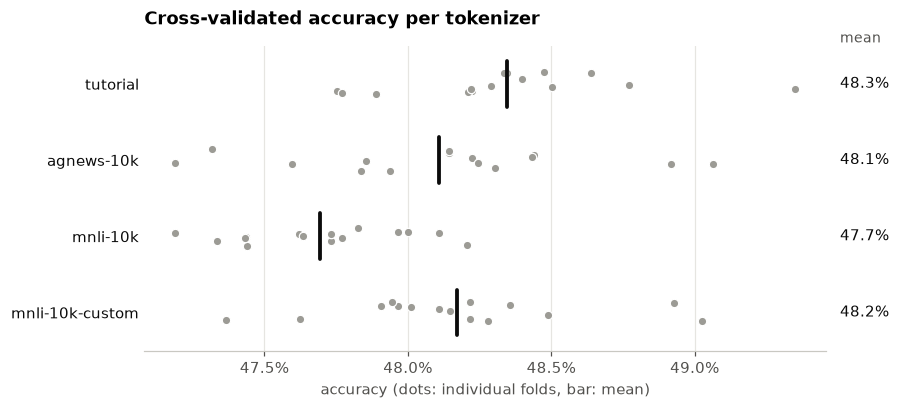

In [17]:
part1.nli.plot_accuracies(accuracies, title="Cross-validated accuracy per tokenizer",
                          save_to=FIG_DIR / "tokenizer_accuracy.png")

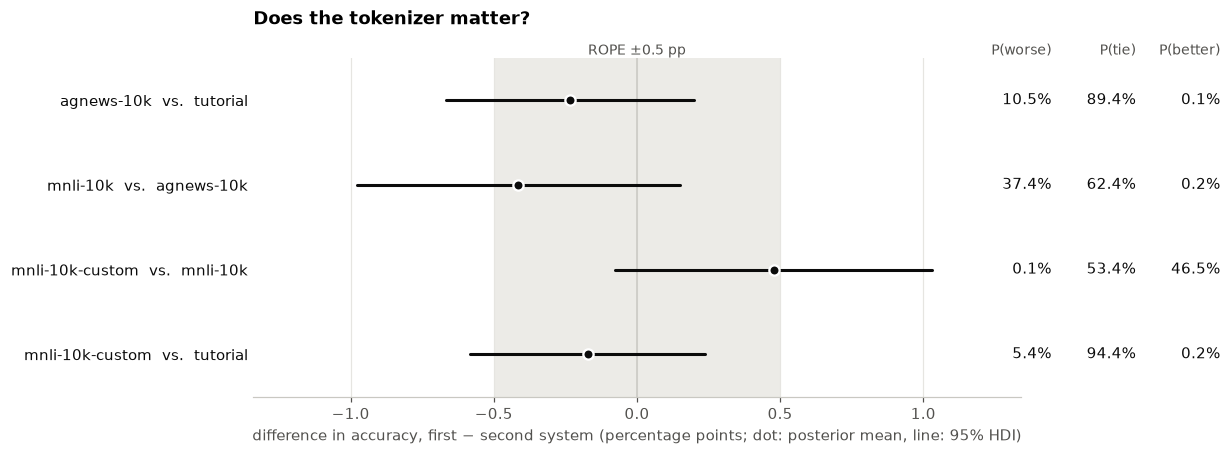

,A,B,mean diff (B-A),95% HDI low,95% HDI high,P(A wins),P(tie),P(B wins)
0,tutorial,agnews-10k,-0.0023,-0.0067,0.0020,0.1048,0.8939,0.0013
1,agnews-10k,mnli-10k,-0.0041,-0.0098,0.0015,0.3740,0.6241,0.0018
2,mnli-10k,mnli-10k-custom,0.0048,-0.0008,0.0103,0.0010,0.5339,0.4651
3,tutorial,mnli-10k-custom,-0.0017,-0.0058,0.0024,0.0539,0.9444,0.0017


In [18]:
# Bayesian comparison (Benavoli et al., 2017), each step against the one before it, plus the overall change
# ROPE: differences smaller than half a percentage point we treat as practically equivalent
ROPE = 0.005
comparisons = [
    ("tutorial", "agnews-10k"),        # effect of the vocabulary size
    ("agnews-10k", "mnli-10k"),        # effect of the training data
    ("mnli-10k", "mnli-10k-custom"),   # effect of lowercasing + pre-tokenization
    ("tutorial", "mnli-10k-custom"),   # overall
]
tokenizer_comparison = part1.nli.compare(accuracies, comparisons, ROPE, runs=len(SEEDS))
part1.nli.plot_comparisons(tokenizer_comparison, ROPE, title="Does the tokenizer matter?",
                           save_to=FIG_DIR / "tokenizer_comparison.png")
display(tokenizer_comparison.round(4))

### Conclusion: which tokenizer?

**Intrinsically the tokenizers are very different.** The tutorial tokenizer (1k tokens) splits MNLI words into ~2.3 pieces each (`▁not h ing`, `▁do es n ' t`), and the negation is no longer visible as a token in 62% of negated hypotheses. Training on MNLI with 10k tokens keeps most words whole (~1.3 tokens per word) and has practically no unknown tokens, also on the unseen genres of dev mismatched. Our custom pre-tokenization additionally collects negation in a handful of tokens (13 instead of 47) and separates punctuation from words.

**Extrinsically they are practically equivalent.** All four reach ~48% accuracy, and with a ROPE of 0.5 percentage points the posterior puts most of its mass on a tie (e.g. 94% tutorial vs. mnli-10k-custom). A plausible explanation: a linear model on bag-of-words cannot relate premise and hypothesis, so it relies on hypothesis cues like negation, and those cues survive even when they are split into pieces (`n ' t` still co-occur). The bottleneck is the representation, not the segmentation.

**Choice: `mnli-10k-custom`.** Since accuracy does not distinguish them, we pick the tokenizer with the better intrinsic properties: whole-word, interpretable features, no unknown tokens on unseen genres, and a single `n't` feature. This also matters for the features we add next: overlap features (does a hypothesis token occur in the premise?) only make sense if tokens are close to words, and they break if the premise has `▁know,` and the hypothesis has `▁know`.

## Baselines

Before we build anything clever, we want to know what an accuracy number actually means on this task. So we start with a few simple models:

- **Majority class**: ignore the text and always predict the label that is most frequent in the training folds. Our training data is balanced, so this should land at about 33%. Everything we build has to beat this.
- **Premise only**: logistic regression on the bag-of-words of the premise alone. Every premise was paired with one hypothesis per label (see EDA), so the premise on its own says nothing about the label. We expect this to be stuck at 33% as well, which makes it a sanity check for our setup.
- **Hypothesis only**: logistic regression on the bag-of-words of the hypothesis alone. NLI is supposed to need both sentences, so whatever this model gets above 33% comes from patterns in how the annotators wrote their hypotheses, like the negation words for contradictions we found in the EDA. [Gururangan et al. (2018)](https://aclanthology.org/N18-2017/) got around 53% on MNLI with a hypothesis-only classifier.
- **Premise + hypothesis**: the same model with both sentences (separate feature blocks, as in the tokenizer comparison). Comparing it to hypothesis-only tells us how much a bag-of-words model actually gets out of the premise.

The majority class baseline is the tutorial's view of a classifier in its simplest form: a probability model whose pmf is just the label frequencies, followed by the most-probable-class decision rule (`part1.nli.MajorityClass`). All baselines use our `mnli-10k-custom` tokenizer, the same sample of 17,000 premises and exactly the same folds as the tokenizer comparison, so their accuracies are paired with every model that comes later.

In [19]:
# setup shared by all baselines: the tokenizer we picked, and one feature matrix per sentence
tokenizer = bpe_tokenizers["mnli-10k-custom"]
X_premise = part1.nli.token_matrix(tokenizer, sample["premise"])
X_hypothesis = part1.nli.token_matrix(tokenizer, sample["hypothesis"])
X_pair = part1.nli.pair_matrix(tokenizer, sample["premise"], sample["hypothesis"])
y = sample["label"]
groups = sample["promptID"]

def cross_validate(make_model, X):
    """cross-validation on our sample, with the same folds as everywhere else in this notebook"""
    return part1.nli.cross_validate(make_model, X, y, groups, num_folds=NUM_FOLDS, seeds=SEEDS)

def logistic_regression():
    return LogisticRegression(max_iter=1000)

baseline_accuracies = {}

In [20]:
# majority class: never looks at the features, only at the labels of the training folds
baseline_accuracies["majority class"] = cross_validate(part1.nli.MajorityClass, X_hypothesis)
print(f"majority class: {np.mean(baseline_accuracies['majority class']):.1%}")

majority class: 33.3%


In [21]:
# premise only: sanity check, the premise alone shouldn't tell us anything about the label
baseline_accuracies["premise only"] = cross_validate(logistic_regression, X_premise)
print(f"premise only: {np.mean(baseline_accuracies['premise only']):.1%}")

premise only: 33.3%


In [22]:
# hypothesis only: the model never sees the premise
baseline_accuracies["hypothesis only"] = cross_validate(logistic_regression, X_hypothesis)
print(f"hypothesis only: {np.mean(baseline_accuracies['hypothesis only']):.1%}")

hypothesis only: 48.8%


In [23]:
# premise + hypothesis: both sentences, each in its own block of features
baseline_accuracies["premise + hypothesis"] = cross_validate(logistic_regression, X_pair)
print(f"premise + hypothesis: {np.mean(baseline_accuracies['premise + hypothesis']):.1%}")

premise + hypothesis: 48.2%


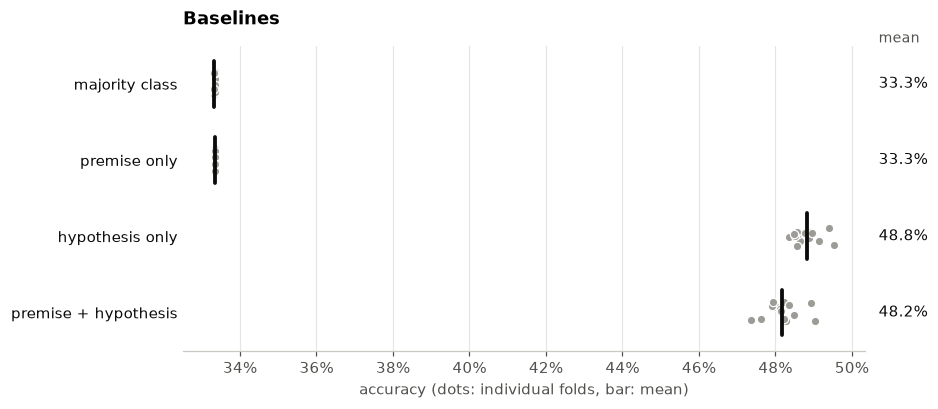

In [24]:
part1.nli.plot_accuracies(baseline_accuracies, title="Baselines", save_to=FIG_DIR / "baselines_accuracy.png")

,A,B,mean diff (B-A),95% HDI low,95% HDI high,P(A wins),P(tie),P(B wins)
0,majority class,premise only,0.0000,-0.0000,0.0001,0.0000,1.0000,0.0
1,majority class,hypothesis only,0.1548,0.1507,0.1590,0.0000,0.0000,1.0
2,hypothesis only,premise + hypothesis,-0.0064,-0.0094,-0.0034,0.8361,0.1639,0.0


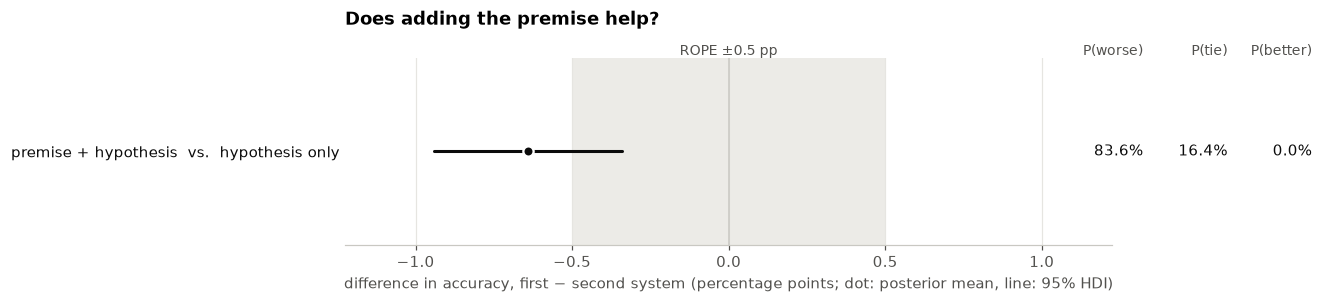

In [25]:
# Bayesian comparison with the same ROPE as for the tokenizers (half a percentage point)
baseline_comparison = part1.nli.compare(baseline_accuracies, [
    ("majority class", "premise only"),          # does the premise alone tell us anything?
    ("majority class", "hypothesis only"),       # how far do we get without the premise?
    ("hypothesis only", "premise + hypothesis"), # does adding the premise help?
], ROPE, runs=len(SEEDS))
display(baseline_comparison.round(4))

# the first two differences are either exactly 0 or about 15 points, so the plot only shows the close call
part1.nli.plot_comparisons(baseline_comparison[baseline_comparison["A"] == "hypothesis only"], ROPE,
                           title="Does adding the premise help?", save_to=FIG_DIR / "baselines_comparison.png")

In [26]:
# which tokens does the hypothesis-only model rely on? we train it once on the whole sample and
# list the tokens with the largest weight per label. we only consider tokens that occur in at least
# 100 hypotheses, otherwise rare word pieces with big weights fill the list
hypothesis_model = logistic_regression().fit(X_hypothesis, y)
hypotheses_per_token = np.asarray((X_hypothesis > 0).sum(axis=0)).ravel()

top_tokens = {}
for label_id, label in enumerate(LABELS):
    weights = np.where(hypotheses_per_token >= 100, hypothesis_model.coef_[label_id], -np.inf)
    top_ids = np.argsort(weights)[::-1][:10]
    top_tokens[label] = [tokenizer.id_to_token(int(i)).replace("▁", "") for i in top_ids]

pd.DataFrame(top_tokens, index=range(1, 11))

,entailment,neutral,contradiction
1,sometimes,also,nothing
2,some,might,never
3,according,%,no
4,may,because,nobody
5,nice,popular,any
6,someone,beautiful,only
7,likely,others,completely
8,longer,many,cannot
9,chance,most,terrible
10,certain,sometimes,not


### Findings

**The setup behaves as it should.** The majority class gets 33.3%, and so does the premise-only model. Every premise comes with one hypothesis of each label, so the premise alone carries no information about the label, and the model does no better than the majority class.

**The hypothesis alone gets us to 48.8%**, 15.5 points above chance, without ever reading the premise. This is the annotation artifact from the EDA showing up in a model: the tokens it relies on most are the same ones we found there. Negations and universal quantifiers for contradiction (*nothing, never, no, nobody, any, only*), hedges and vague words for entailment (*some, may, sometimes, likely*), and added information for neutral (*also, because, many, most*). Gururangan et al. (2018) report about 53% for a hypothesis-only model on MNLI; we are a few points lower, which is not surprising since we train on 52k pairs instead of all 393k.

**Adding the premise doesn't help, it even hurts a bit.** Premise + hypothesis reaches 48.2%, 0.6 points below hypothesis-only. With our ROPE of half a point, the posterior says there is an 84% chance it is really worse and a 16% chance of a practical tie, and no chance at all that it is better. In hindsight this makes sense: a linear model over two separate bags of words can only learn "this word in the premise" and "that word in the hypothesis" independently, never "this word appears in both". The premise features on their own are useless (see premise-only), so the extra 10,000 of them mostly give the model more room to overfit.

**What this means for the rest of the project.** The real bar to beat is not 33% but the ~49% of hypothesis-only. A model is only doing something NLI-like if it gets above that, and for that it has to relate the two sentences to each other. That is exactly what we try next: overlap features on the representation side, and the interaction MLP on the architecture side.

## Representations

The baselines showed that a bag-of-words over both sentences does no better than looking at the hypothesis alone. In this section we change only the representation and keep everything else fixed: the `mnli-10k-custom` tokenizer, logistic regression, the same sample and the same folds. We compare the two representations from the tutorial with one of our own, which is designed to relate the two sentences to each other.

### Token indicators

As in the tutorial: one feature per token in the vocabulary, 1 if the token occurs in the sentence and 0 otherwise. Premise and hypothesis each get their own block, so a pair has 2 × 10,000 features.

In [27]:
representation_accuracies = {}

X_indicators = part1.nli.pair_matrix(tokenizer, sample["premise"], sample["hypothesis"], binary=True)
representation_accuracies["token indicators"] = cross_validate(logistic_regression, X_indicators)
print(f"token indicators: {np.mean(representation_accuracies['token indicators']):.1%}")

token indicators: 48.3%


### Bag-of-words

Also from the tutorial: the same features, but counting how often each token occurs instead of only whether it occurs. This is exactly our premise + hypothesis baseline, so we reuse its accuracies instead of training the same models again.

In [28]:
# same features, same model and same folds as the "premise + hypothesis" baseline, so the results are identical
representation_accuracies["bag-of-words"] = baseline_accuracies["premise + hypothesis"]
print(f"bag-of-words: {np.mean(representation_accuracies['bag-of-words']):.1%}")

bag-of-words: 48.2%


### Overlap features (our representation)

The two representations above describe each sentence on its own. For NLI, though, what matters is how the hypothesis relates to the premise: an entailed hypothesis mostly reuses the premise's words, a neutral one adds new information, and a contradiction often adds a negation (see EDA). So our representation describes the hypothesis *in terms of the premise*:

- **Shared words**: bag-of-words of the hypothesis tokens that also occur in the premise.
- **New words**: bag-of-words of the hypothesis tokens that do *not* occur in the premise. This is where the model can learn that a new *not* or *never* points to a contradiction, while a *not* that was already in the premise means much less.
- **7 overlap statistics**: the share of hypothesis words that occur in the premise, the number of new words, the lengths of both sentences, whether each sentence contains a negation, and whether exactly one of them does. Counts and lengths are log-scaled so all values stay small.

We leave out the bag-of-words of the premise itself. The premise-only baseline showed it carries no information about the label on its own, and in the premise + hypothesis baseline it only added noise. The premise still shapes the representation, because it decides which hypothesis words count as shared and which as new.

The code is in `part1.nli.overlap_features`.

In [29]:
shared, new, overlap_statistics = part1.nli.overlap_features(tokenizer, sample["premise"], sample["hypothesis"])
X_overlap = hstack([shared, new, overlap_statistics]).tocsr()
print(f"{X_overlap.shape[1]:,} features per pair")

# do the statistics actually differ between the labels? (means over our sample)
statistics_by_label = pd.DataFrame(overlap_statistics.toarray(), columns=part1.nli.OVERLAP_STATISTICS)
statistics_by_label["label"] = sample["label_name"].to_numpy()
statistics_by_label.groupby("label").mean().T[LABELS].round(2)

20,007 features per pair


label,entailment,neutral,contradiction
share of hypothesis words in premise,0.63,0.42,0.48
new words in hypothesis (log),1.44,1.97,1.74
premise length (log),3.11,3.11,3.11
hypothesis length (log),2.56,2.63,2.52
negation in premise,0.20,0.20,0.20
negation in hypothesis,0.14,0.15,0.39
negation in only one,0.13,0.21,0.47


In [30]:
representation_accuracies["overlap (ours)"] = cross_validate(logistic_regression, X_overlap)
print(f"overlap (ours): {np.mean(representation_accuracies['overlap (ours)']):.1%}")

overlap (ours): 59.6%


#### Which parts of the overlap representation matter?

Our representation changes several things at once compared to bag-of-words. To see what each change contributes, we add them one at a time (a small ablation).

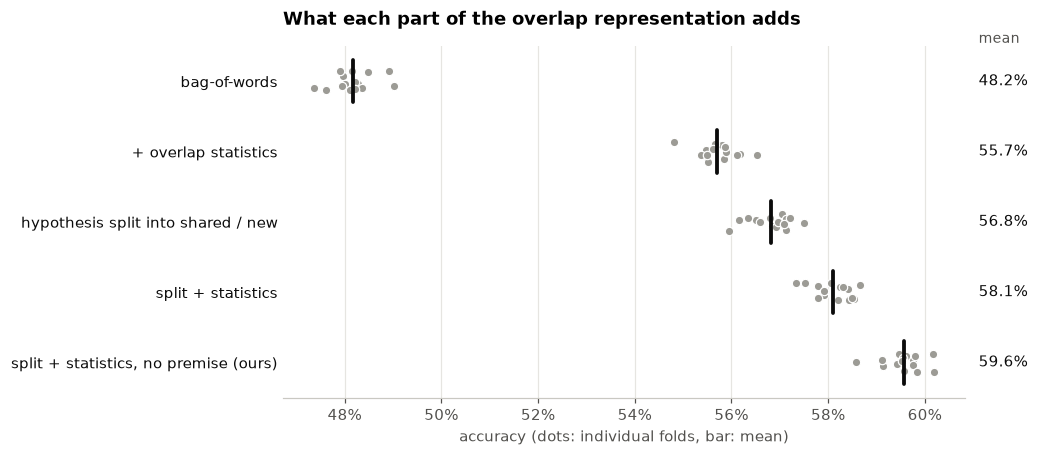

In [31]:
# start from bag-of-words and change one thing at a time
ablation_accuracies = {
    "bag-of-words": representation_accuracies["bag-of-words"],
    "+ overlap statistics": cross_validate(logistic_regression, hstack([X_pair, overlap_statistics]).tocsr()),
    "hypothesis split into shared / new": cross_validate(logistic_regression, hstack([X_premise, shared, new]).tocsr()),
    "split + statistics": cross_validate(logistic_regression, hstack([X_premise, shared, new, overlap_statistics]).tocsr()),
    "split + statistics, no premise (ours)": representation_accuracies["overlap (ours)"],
}
part1.nli.plot_accuracies(ablation_accuracies, title="What each part of the overlap representation adds",
                          save_to=FIG_DIR / "representations_ablation.png")

### Comparison of representations

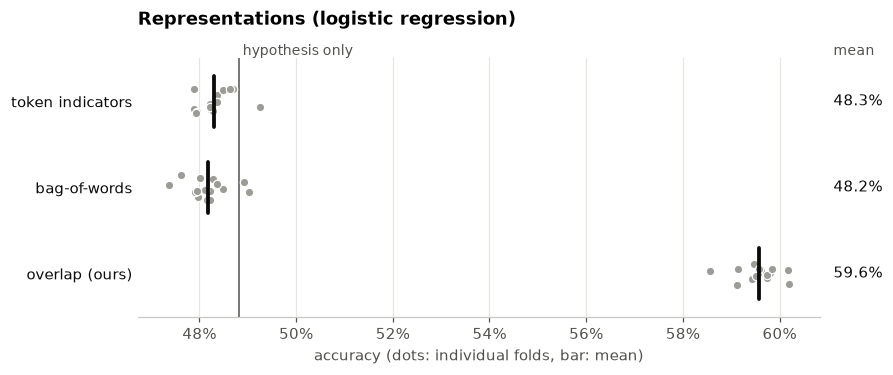

,A,B,mean diff (B-A),95% HDI low,95% HDI high,P(A wins),P(tie),P(B wins)
0,bag-of-words,token indicators,0.0014,-0.0015,0.0042,0.0002,0.9915,0.0084
1,bag-of-words,overlap (ours),0.1139,0.1079,0.1200,0.0000,0.0000,1.0000
2,hypothesis only,overlap (ours),0.1075,0.1025,0.1125,0.0000,0.0000,1.0000


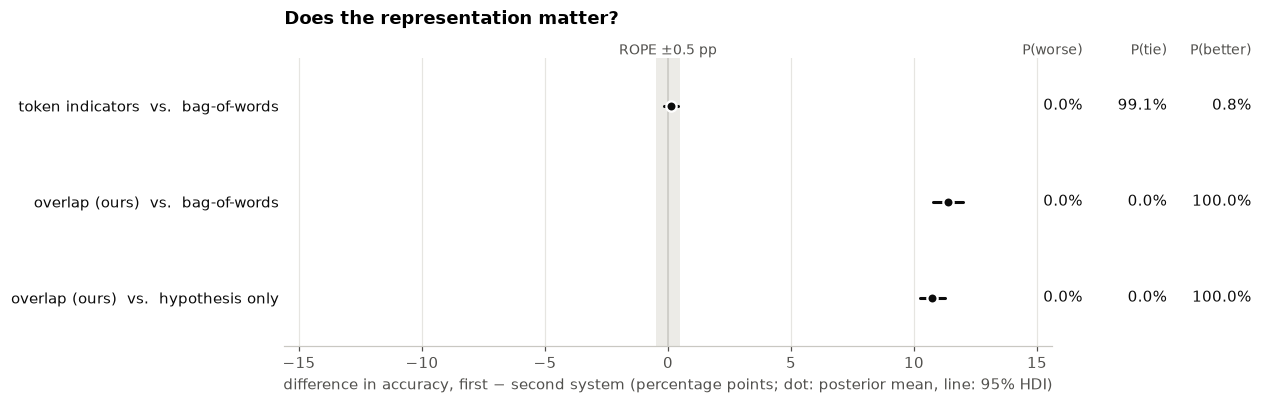

In [32]:
part1.nli.plot_accuracies(representation_accuracies, title="Representations (logistic regression)",
                          reference_lines={"hypothesis only": np.mean(baseline_accuracies["hypothesis only"])},
                          save_to=FIG_DIR / "representations_accuracy.png")

representation_comparison = part1.nli.compare({**baseline_accuracies, **representation_accuracies}, [
    ("bag-of-words", "token indicators"),  # does counting tokens matter, or only whether they occur?
    ("bag-of-words", "overlap (ours)"),     # our representation vs. the tutorial's
    ("hypothesis only", "overlap (ours)"),  # do we beat the bar set by the baselines?
], ROPE, runs=len(SEEDS))
display(representation_comparison.round(4))
part1.nli.plot_comparisons(representation_comparison, ROPE, title="Does the representation matter?",
                           save_to=FIG_DIR / "representations_comparison.png")

### Which representation works best, and why?

**Counting tokens or only marking them makes no difference.** Token indicators (48.3%) and bag-of-words (48.2%) are a practical tie, with 99% of the posterior inside the ROPE. Our sentences are short, so 91% of the non-zero counts in the bag-of-words are 1 anyway, and the two representations are nearly the same.

**Relating the two sentences makes a big difference.** The overlap representation reaches 59.6%, 11.4 points above bag-of-words and 10.8 points above the hypothesis-only baseline, with the whole posterior far outside the ROPE. This is the first model that clearly does more than pick up artifacts in the hypothesis. The statistics per label show why it works: entailed hypotheses share 63% of their words with the premise against 42% for neutral ones, and in contradictions the two sentences disagree about negation 47% of the time against 13% for entailment.

**Every part of the representation helps.** Adding just the 7 overlap statistics to bag-of-words is already worth 7.5 points (55.7%). Splitting the hypothesis into shared and new words is worth a bit more on its own (56.8%), and both together give 58.1%. Dropping the premise bag-of-words then adds another 1.5 points, which fits what the baselines told us: on its own, the premise is noise.

From here on, the overlap representation is our default.

## Architectures

So far every model was a log-linear one. Now we vary the model and compare three architectures: the log-linear model and the one-hidden-layer MLP from the tutorial, and an MLP of our own that compares the premise and the hypothesis inside the network.

One complication: our interaction MLP needs the premise and the hypothesis as two separate inputs, so it can't run on the overlap representation (which has already mixed them). That actually makes for an interesting question. The overlap representation is a relation between the sentences that *we* designed by hand; can a network *learn* such a relation by itself from the plain bag-of-words? So we run each architecture on bag-of-words, and the log-linear model and the MLP also on the overlap representation:

| | bag-of-words | overlap |
|---|---|---|
| log-linear | ✓ (from above) | ✓ (from above) |
| MLP | ✓ | ✓ |
| interaction MLP | ✓ | – |

Everything else stays fixed: same tokenizer, sample and folds.

### Log-linear model

Softmax regression as in the tutorial. We already trained it on both representations with exactly these folds, so we reuse those accuracies.

In [33]:
architecture_accuracies = {
    "log-linear / bag-of-words": representation_accuracies["bag-of-words"],
    "log-linear / overlap": representation_accuracies["overlap (ours)"],
}
for name, accs in architecture_accuracies.items():
    print(f"{name}: {np.mean(accs):.1%}")

log-linear / bag-of-words: 48.2%
log-linear / overlap: 59.6%


### MLP with one hidden layer

The tutorial's `part1.smlp.SparseMLP`: a sparse input layer into 128 hidden units with ReLU and dropout, then softmax over the three labels. We keep the tutorial's training settings (AdamW with learning rate 1e-4 and weight decay 1e-4, batch size 64, dropout 0.1) and train with its own `train_one_epoch` and `evaluate` functions.

We changed one thing about how the training is set up. The tutorial's `train_neural_network_model` picks the best epoch by the loss on the validation fold, and then reports the accuracy on that same fold. That means the validation fold helps choose the model it is evaluated on, which makes the score a bit optimistic. Our wrapper `part1.nli.NeuralClassifier` instead holds out 10% of the *training* fold's premises and stops when the loss there hasn't improved for 2 epochs (at most 20). The validation fold is only used for the final accuracy.

We hold out whole premises for the same reason we group the folds. When we first held out random pairs instead, the MLP on bag-of-words looked much worse on the held-out pairs (~39%) than on the real validation fold (~49%). Each premise has one hypothesis per label, so if a premise's other two hypotheses are in training, a model that memorises premise words learns "this premise means those two labels" and gets pushed *away* from the held-out label.

In [34]:
HIDDEN_DIM = 128
DROPOUT = 0.1

def mlp():
    """the tutorial's one-hidden-layer MLP, with fit/predict so it works with our cross-validation"""
    return part1.nli.NeuralClassifier(
        lambda input_dim: part1.smlp.SparseMLP(input_dim, HIDDEN_DIM, num_classes=3, dropout=DROPOUT))

In [36]:
# this takes a few minutes: 2 x 15 networks
architecture_accuracies["MLP / bag-of-words"] = cross_validate(mlp, X_pair)
architecture_accuracies["MLP / overlap"] = cross_validate(mlp, X_overlap)
for name in ["MLP / bag-of-words", "MLP / overlap"]:
    print(f"{name}: {np.mean(architecture_accuracies[name]):.1%}")

MLP / bag-of-words: 51.6%
MLP / overlap: 61.8%


### Interaction MLP (our architecture)

The tutorial's MLP sees the premise and hypothesis features side by side and has to discover any relation between them on its own. Our interaction MLP builds the comparison into the architecture, following the way sentence-pair models are commonly set up ([Conneau et al., 2017](https://aclanthology.org/D17-1070/)):

1. The **same encoder** (sparse input layer with 128 ReLU units, i.e. the first layer of the tutorial's MLP) turns the premise into a vector $p$ and the hypothesis into a vector $h$. Because the weights are shared, the same word ends up in the same place in both vectors.
2. The two are combined as $[p,\ h,\ |p - h|,\ p \odot h]$. The difference $|p - h|$ shows where the sentences disagree, and the product $p \odot h$ where they agree, which is a learned version of what our overlap features measure.
3. A hidden layer (128 ReLU units, dropout) and a softmax give the label probabilities.

The model is `part1.nli.InteractionMLP`. It is trained exactly like the MLP above.

In [37]:
VOCAB_SIZE = tokenizer.get_vocab_size()

def interaction_mlp():
    """our interaction MLP: shared sentence encoder, then [p, h, |p - h|, p * h] into a hidden layer"""
    return part1.nli.NeuralClassifier(
        lambda input_dim: part1.nli.InteractionMLP(VOCAB_SIZE, HIDDEN_DIM, num_classes=3, dropout=DROPOUT))

# what the network looks like
example = part1.nli.InteractionMLP(VOCAB_SIZE, HIDDEN_DIM, num_classes=3, dropout=DROPOUT)
print(f"shared encoder: {example.weight.shape[0]:,} x {example.weight.shape[1]} weights, used for premise and hypothesis")
print(f"classifier on [p, h, |p - h|, p * h]: {example.classifier}")
print(f"parameters in total: {sum(p.numel() for p in example.parameters()):,}")

shared encoder: 10,000 x 128 weights, used for premise and hypothesis
classifier on [p, h, |p - h|, p * h]: Sequential(
  (0): Dropout(p=0.1, inplace=False)
  (1): Linear(in_features=512, out_features=128, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.1, inplace=False)
  (4): Linear(in_features=128, out_features=3, bias=True)
  (5): LogSoftmax(dim=-1)
)
parameters in total: 1,346,179


In [38]:
# this takes a few minutes as well: 15 networks
architecture_accuracies["interaction MLP / bag-of-words"] = cross_validate(interaction_mlp, X_pair)
print(f"interaction MLP / bag-of-words: {np.mean(architecture_accuracies['interaction MLP / bag-of-words']):.1%}")

interaction MLP / bag-of-words: 57.6%


### Comparison of architectures

representation,bag-of-words,overlap
architecture,,
log-linear,48.2%,59.6%
MLP,51.6%,61.8%
interaction MLP,57.6%,–


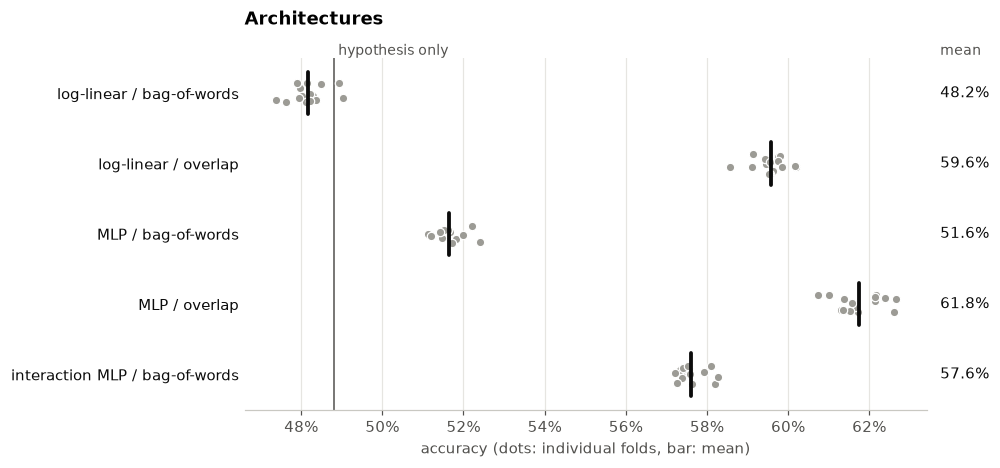

,A,B,mean diff (B-A),95% HDI low,95% HDI high,P(A wins),P(tie),P(B wins)
0,log-linear / bag-of-words,MLP / bag-of-words,0.0346,0.0309,0.0383,0.0000,0.0000,1.0
1,MLP / bag-of-words,interaction MLP / bag-of-words,0.0599,0.0571,0.0626,0.0000,0.0000,1.0
2,log-linear / overlap,interaction MLP / bag-of-words,-0.0195,-0.0253,-0.0136,0.9999,0.0001,0.0
3,log-linear / overlap,MLP / overlap,0.0219,0.0176,0.0263,0.0000,0.0000,1.0


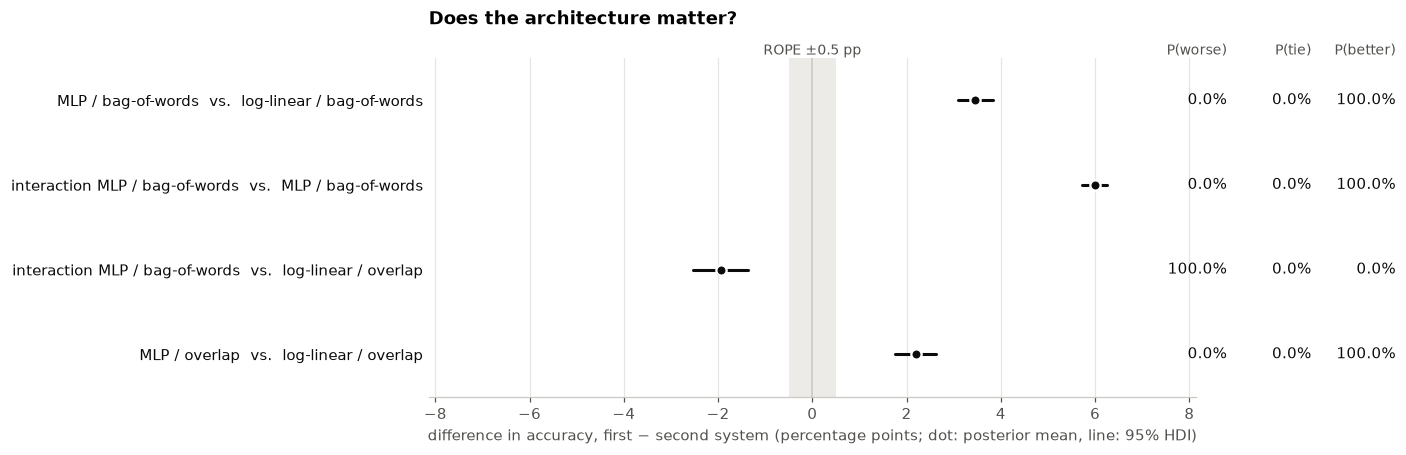

In [39]:
# overview: architectures in the rows, representations in the columns
summary = pd.DataFrame(
    [(*name.split(" / "), np.mean(accs)) for name, accs in architecture_accuracies.items()],
    columns=["architecture", "representation", "accuracy"],
)
display(summary.pivot(index="architecture", columns="representation", values="accuracy")
        .loc[["log-linear", "MLP", "interaction MLP"]].style.format("{:.1%}", na_rep="–"))

part1.nli.plot_accuracies(architecture_accuracies, title="Architectures",
                          reference_lines={"hypothesis only": np.mean(baseline_accuracies["hypothesis only"])},
                          save_to=FIG_DIR / "architectures_accuracy.png")

architecture_comparison = part1.nli.compare(architecture_accuracies, [
    ("log-linear / bag-of-words", "MLP / bag-of-words"),         # does a hidden layer help on bag-of-words?
    ("MLP / bag-of-words", "interaction MLP / bag-of-words"),    # does comparing the sentences in the network help?
    ("log-linear / overlap", "interaction MLP / bag-of-words"),  # learned relation vs. our handcrafted one
    ("log-linear / overlap", "MLP / overlap"),                   # does a hidden layer help on top of our features?
], ROPE, runs=len(SEEDS))
display(architecture_comparison.round(4))
part1.nli.plot_comparisons(architecture_comparison, ROPE, title="Does the architecture matter?",
                           save_to=FIG_DIR / "architectures_comparison.png")

### Which architecture works best, and why?

**A hidden layer helps, on both representations.** On bag-of-words the MLP gets 51.6%, about 3.5 points more than the log-linear model. That is the first time a model that sees plain bag-of-words beats hypothesis-only (48.8%). A hidden unit can combine premise and hypothesis features, so the network picks up some interactions between the two sentences that a linear model can't express. On the overlap representation the MLP adds another 2.2 points (61.8%), our best result so far. In both cases the whole posterior lies outside the ROPE.

**Building the comparison into the network helps a lot more.** From the same bag-of-words, the interaction MLP reaches 57.6%, 6 points above the plain MLP. Sharing the encoder and comparing $p$ and $h$ explicitly lets the network work out by itself much of what our overlap features compute by hand.

**But our handcrafted features still win.** The interaction MLP stays 2 points below a plain log-linear model on the overlap representation (59.6%), and the posterior is practically certain about that. With about 47k training pairs per fold, telling the model directly which words are shared and which are new works better than letting it learn that from scratch. It would be interesting to see whether this changes with all 393k training pairs, where a learned comparison has far more data to work with.

**Best system: the MLP on the overlap representation (61.8%).** This is the system we take into the final evaluation on the dev sets.

## Results

The sections above each changed one design choice at a time. Here we put everything together: all systems side by side, a closer Bayesian look at how sure we are about the best one, a single evaluation on the two dev sets that we haven't touched so far, and an analysis of the errors that remain.

### All systems

Every system we cross-validated, from best to worst (mean and standard deviation over the same 15 folds).

,mean accuracy,std over folds
MLP / overlap,61.8%,0.6%
log-linear / overlap,59.6%,0.4%
interaction MLP / bag-of-words,57.6%,0.3%
MLP / bag-of-words,51.6%,0.4%
hypothesis only,48.8%,0.3%
log-linear / token indicators,48.3%,0.3%
log-linear / bag-of-words,48.2%,0.4%
premise only,33.3%,0.0%
majority class,33.3%,0.0%


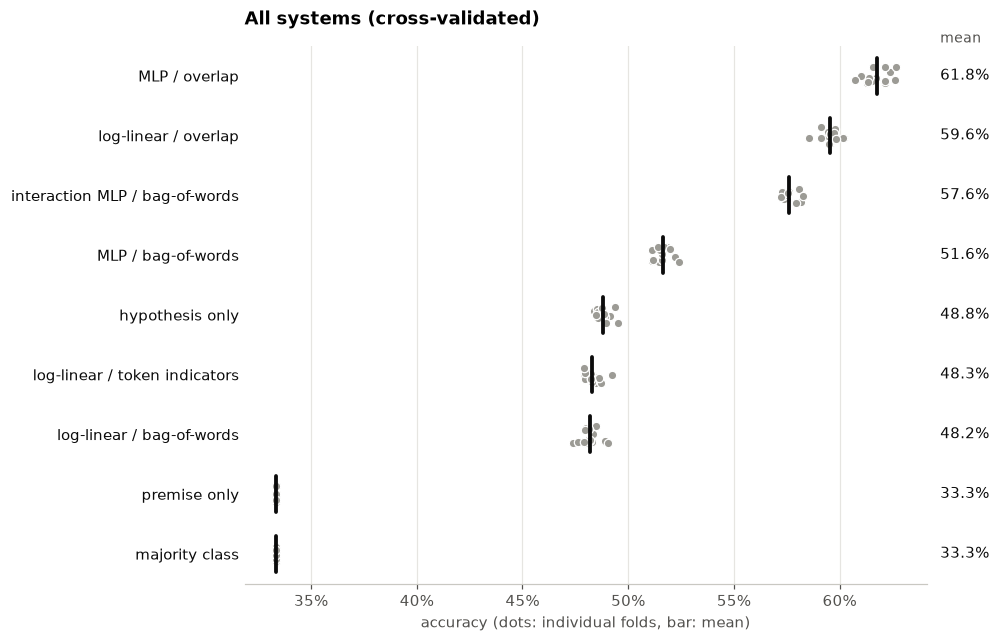

In [40]:
all_accuracies = {
    "majority class": baseline_accuracies["majority class"],
    "premise only": baseline_accuracies["premise only"],
    "hypothesis only": baseline_accuracies["hypothesis only"],
    "log-linear / token indicators": representation_accuracies["token indicators"],
    **architecture_accuracies,
}
# best system first
all_accuracies = dict(sorted(all_accuracies.items(), key=lambda item: -np.mean(item[1])))

results_table = pd.DataFrame({
    "mean accuracy": [np.mean(accs) for accs in all_accuracies.values()],
    "std over folds": [np.std(accs) for accs in all_accuracies.values()],
}, index=list(all_accuracies))
display(results_table.style.format("{:.1%}"))

part1.nli.plot_accuracies(all_accuracies, title="All systems (cross-validated)",
                          save_to=FIG_DIR / "all_systems_accuracy.png")

### Bayesian analysis

**Choosing the ROPE.** For all comparisons we treat differences smaller than ±0.5 percentage points as practically equivalent. We have two reasons for this size:

- **It matches the precision of a single evaluation.** On a dev set of ~9,800 pairs, the standard error of an accuracy around 60% is $\sqrt{0.6 \cdot 0.4 / 9800} \approx 0.5$ points. A smaller difference between two systems could not reliably be seen on held-out data anyway.
- **It is about the noise we see between folds.** The standard deviation of the accuracy over our 15 folds is 0.3 to 0.6 points for every system (see the table above), so differences below that are within the variation that comes from which premises end up in which fold.

It is also the value the tutorial used. Below we compare our best system with its closest competitor, with the strongest model that doesn't use our features, with the tutorial's setup and with the hypothesis-only baseline. Because the choice of ROPE is a judgement call, we repeat the comparison with half and twice the size to see whether any conclusion depends on it.

,A,B,mean diff (B-A),95% HDI low,95% HDI high,P(A wins),P(tie),P(B wins)
0,log-linear / overlap,MLP / overlap,0.0219,0.0176,0.0263,0.0,0.0,1.0
1,interaction MLP / bag-of-words,MLP / overlap,0.0414,0.0345,0.0483,0.0,0.0,1.0
2,log-linear / bag-of-words,MLP / overlap,0.1359,0.1291,0.1427,0.0,0.0,1.0
3,hypothesis only,MLP / overlap,0.1294,0.1236,0.1353,0.0,0.0,1.0


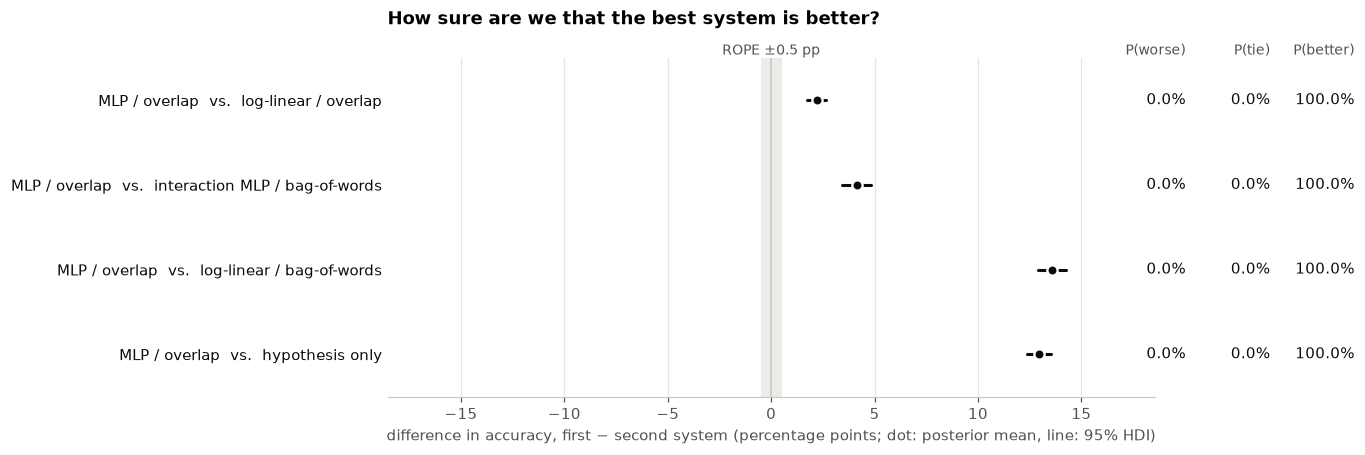

In [41]:
BEST = "MLP / overlap"
key_comparisons = [
    ("log-linear / overlap", BEST),            # closest competitor: does the hidden layer matter?
    ("interaction MLP / bag-of-words", BEST),  # best model without our features: learned vs. handcrafted relation
    ("log-linear / bag-of-words", BEST),       # the tutorial's setup
    ("hypothesis only", BEST),                 # the bar set by the annotation artifacts
]
key_comparison = part1.nli.compare(all_accuracies, key_comparisons, ROPE, runs=len(SEEDS))
display(key_comparison.round(4))
part1.nli.plot_comparisons(key_comparison, ROPE, title="How sure are we that the best system is better?",
                           save_to=FIG_DIR / "results_comparison.png")

In [42]:
# sensitivity check: does any conclusion change with half or twice the ROPE?
sensitivity = pd.concat([
    part1.nli.compare(all_accuracies, key_comparisons, rope, runs=len(SEEDS)).assign(ROPE=f"±{100 * rope:g} pp")
    for rope in [ROPE / 2, ROPE, ROPE * 2]
])
sensitivity["comparison"] = sensitivity["B"] + "  vs.  " + sensitivity["A"]
display(sensitivity.pivot(index="comparison", columns="ROPE", values=["P(B wins)", "P(tie)"]).round(3))

P(B wins)                \
ROPE                                                ±0.25 pp ±0.5 pp ±1 pp   
comparison                                                                   
MLP / overlap  vs.  hypothesis only                      1.0     1.0   1.0   
MLP / overlap  vs.  interaction MLP / bag-of-words       1.0     1.0   1.0   
MLP / overlap  vs.  log-linear / bag-of-words            1.0     1.0   1.0   
MLP / overlap  vs.  log-linear / overlap                 1.0     1.0   1.0   

                                                     P(tie)                
ROPE                                               ±0.25 pp ±0.5 pp ±1 pp  
comparison                                                                 
MLP / overlap  vs.  hypothesis only                     0.0     0.0   0.0  
MLP / overlap  vs.  interaction MLP / bag-of-words      0.0     0.0   0.0  
MLP / overlap  vs.  log-linear / bag-of-words           0.0     0.0   0.0  
MLP / overlap  vs.  log-linear / overlap                0.0     0.0   0.0

**The best system really is the best, and the ROPE doesn't change that.** The MLP on the overlap representation beats its closest competitor, the log-linear model on the same features, by 2.2 points (95% HDI 1.8 to 2.6). It beats the interaction MLP by 4.1 points (3.5 to 4.8), the tutorial's setup by 13.6 points and the hypothesis-only baseline by 12.9 points. In all four comparisons the whole posterior lies above the ROPE, and that stays true with a ROPE of ±0.25 or ±1 point, so none of these conclusions hinges on our choice of ROPE size.

### Held-out evaluation: dev matched and dev mismatched

Cross-validation told us which design choices matter, but all of those choices were made by looking at the same folds. Now we test the systems on data that played no part in any decision: the two public dev sets, which we haven't used until now (apart from counting tokens per word in the tokenizer section, which uses no labels).

- **Dev matched**: the same five genres as the training data.
- **Dev mismatched**: five genres that never appear in training (letters, face-to-face conversations, the 9/11 report, OUP non-fiction, Verbatim magazine).

We train each system once on our whole sample (17,000 premises, ~52k pairs) and evaluate it exactly once on each dev set. Each dev set has about 9,800 pairs, so every accuracy comes with a 95% interval of roughly ±1 point.

In [43]:
from sklearn.metrics import accuracy_score

dev = {split: df[df["split"] == split] for split in ["dev matched", "dev mismatched"]}

def build_features(frame):
    """all representations we need for a set of pairs, built with our tokenizer (nothing is fitted on the data)"""
    shared, new, statistics = part1.nli.overlap_features(tokenizer, frame["premise"], frame["hypothesis"])
    return {
        "hypothesis": part1.nli.token_matrix(tokenizer, frame["hypothesis"]),
        "bag-of-words": part1.nli.pair_matrix(tokenizer, frame["premise"], frame["hypothesis"]),
        "overlap": hstack([shared, new, statistics]).tocsr(),
        "statistics": pd.DataFrame(statistics.toarray(), columns=part1.nli.OVERLAP_STATISTICS, index=frame.index),
    }

train_features = build_features(sample)
dev_features = {split: build_features(frame) for split, frame in dev.items()}

# system name: (untrained model, representation it uses)
final_systems = {
    "majority class": (part1.nli.MajorityClass(), "hypothesis"),
    "hypothesis only": (logistic_regression(), "hypothesis"),
    "log-linear / bag-of-words": (logistic_regression(), "bag-of-words"),
    "MLP / bag-of-words": (mlp(), "bag-of-words"),
    "interaction MLP / bag-of-words": (interaction_mlp(), "bag-of-words"),
    "log-linear / overlap": (logistic_regression(), "overlap"),
    "MLP / overlap": (mlp(), "overlap"),
}

# train once on the whole sample, predict once on each dev set (takes a few minutes because of the networks)
dev_predictions = {split: {} for split in dev}
rows = []
for name, (model, representation) in final_systems.items():
    if isinstance(model, part1.nli.NeuralClassifier):
        model.fit(train_features[representation], y, groups=groups)
    else:
        model.fit(train_features[representation], y)
    row = {"cross-validation": np.mean(all_accuracies[name])}
    for split, frame in dev.items():
        dev_predictions[split][name] = model.predict(dev_features[split][representation])
        row[split] = accuracy_score(frame["label"], dev_predictions[split][name])
    rows.append(pd.Series(row, name=name))

dev_results = pd.DataFrame(rows).sort_values("dev matched", ascending=False)
dev_results["matched − mismatched"] = dev_results["dev matched"] - dev_results["dev mismatched"]
display(dev_results.style.format("{:.1%}"))

,cross-validation,dev matched,dev mismatched,matched − mismatched
MLP / overlap,61.8%,61.1%,61.8%,-0.7%
log-linear / overlap,59.6%,59.5%,59.4%,0.1%
interaction MLP / bag-of-words,57.6%,57.0%,57.8%,-0.7%
MLP / bag-of-words,51.6%,52.2%,52.1%,0.1%
hypothesis only,48.8%,48.7%,48.7%,0.0%
log-linear / bag-of-words,48.2%,48.6%,48.2%,0.3%
majority class,33.3%,35.4%,35.2%,0.2%


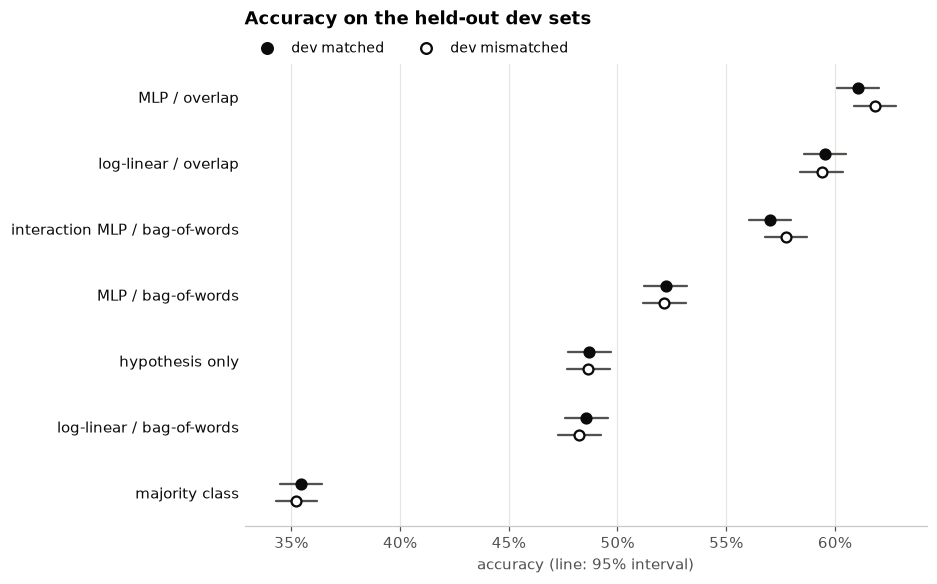

In [44]:
part1.nli.plot_dev_accuracies(dev_results, {split: len(frame) for split, frame in dev.items()},
                              title="Accuracy on the held-out dev sets", save_to=FIG_DIR / "dev_accuracy.png")

**The cross-validation results hold up on unseen data.** On dev matched, every system lands within 0.7 points of its cross-validated accuracy, and the ranking of the systems is exactly the same. So we see no sign that choosing our designs on the cross-validation folds made the numbers too optimistic. The one bigger change is the majority class (33.3% → 35.4%), and that is only because entailment is slightly more frequent in the dev sets than in our balanced training data (see EDA).

**No drop on the unseen genres.** On dev mismatched, whose five genres never appear in training, the systems do as well as on dev matched: the differences are at most 0.7 points, which is inside the ±1-point intervals. Our best system even scores slightly higher there (61.8% vs. 61.1%). In hindsight this fits what our models rely on: whether the hypothesis reuses the premise's words, whether a negation appears, and the annotation artifacts in the hypothesis. None of that depends on the topic of the text, and our BPE tokenizer can still split words it has never seen into known pieces.

**Final numbers for our best system (MLP on the overlap representation): 61.1% on dev matched and 61.8% on dev mismatched**, against 48.7% for hypothesis-only and 35% for always predicting the majority class.

### Error analysis

Accuracy alone doesn't say *which* mistakes a system makes. We look at the errors of our best system on dev matched, and compare it to the hypothesis-only baseline to see where the improvement comes from.

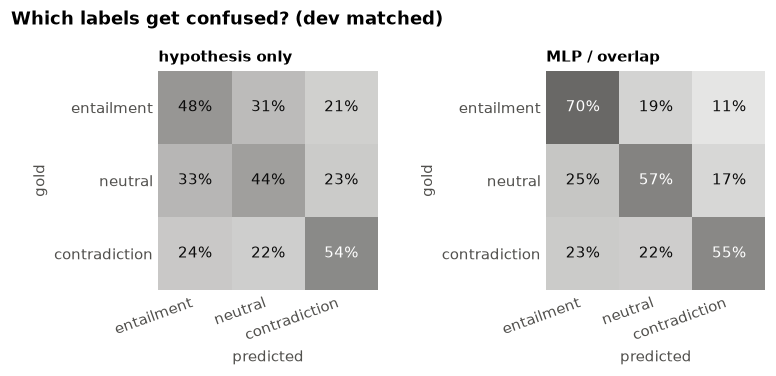

In [45]:
dev_matched = dev["dev matched"]
part1.nli.plot_confusion_matrices(
    {name: dev_predictions["dev matched"][name] for name in ["hypothesis only", BEST]},
    dev_matched["label"], LABELS, title="Which labels get confused? (dev matched)",
    save_to=FIG_DIR / "confusion_matrices.png",
)

In [46]:
# accuracy of the best system per genre, on both dev sets
per_genre = pd.concat([
    frame.assign(correct=dev_predictions[split][BEST] == frame["label"].to_numpy())
    for split, frame in dev.items()
]).groupby(["split", "genre"])["correct"].mean().rename("accuracy").to_frame()
display(per_genre.sort_values(["split", "accuracy"], ascending=[True, False]).style.format("{:.1%}"))

In [47]:
# how does the best system use word overlap? for each gold label, we split the pairs by the share of
# hypothesis words that also occur in the premise, and look at how often the system predicts "entailment"
analysis = dev_matched.assign(
    predicted=[LABELS[i] for i in dev_predictions["dev matched"][BEST]],
    overlap=dev_features["dev matched"]["statistics"]["share of hypothesis words in premise"],
)
analysis["overlap level"] = pd.cut(analysis["overlap"], bins=[-0.01, 1/3, 2/3, 1.0], labels=["low (≤ 1/3)", "medium", "high (> 2/3)"])
analysis["predicted entailment"] = analysis["predicted"] == "entailment"
analysis["correct"] = analysis["predicted"] == analysis["label_name"]

summary = analysis.groupby(["label_name", "overlap level"], observed=True).agg(
    pairs=("correct", "size"), accuracy=("correct", "mean"), predicted_entailment=("predicted entailment", "mean"),
).rename(columns={"predicted_entailment": "predicted entailment"}).reindex(LABELS, level=0)
display(summary.style.format({"accuracy": "{:.1%}", "predicted entailment": "{:.1%}"}))

In [48]:
# a few typical mistakes: contradictions and neutral pairs with high overlap that the system calls entailment
mistakes = analysis[(analysis["overlap level"] == "high (> 2/3)") & (analysis["label_name"] != "entailment")
                    & (analysis["predicted"] == "entailment")]
mistakes.sample(6, random_state=0)[["premise", "hypothesis", "label_name", "predicted", "overlap"]].round(2)

,premise,hypothesis,label_name,predicted,overlap
402106,"But, when I discovered that it was known all over the village that it was John who was attracted by the farmer's pretty wife, his silence bore quite a different interpretation.",The entire village was attracted to the farmer's wife.,neutral,entailment,0.80
393443,The H-2A worker must depart the country and is subject to deportation for failing to do so.,The H-2A worker is being forced to enter the country for work.,contradiction,entailment,0.69
401487,"And yet, we still lack a set of global accounting and reporting standards that reflects the globalization of economies, enterprises, and markets.","We have comprehensive global reporting standards that reflects the globalization of economies, and markets.",contradiction,entailment,0.87
398352,"Watch for Pagla Jhora, the Mad Torrent, just after Gladstone's Rock (shaped like the statesman's head).",The Mad Torrent comes before Gladstone's Rock.,contradiction,entailment,0.80
393460,"' Blankley replies, And there are fund-raisers going out in other parts of the country to raise 'The conservatives are coming, the conservatives are coming.","Blankley replies, there are no fundraisers in other parts of the country to raise ""the conservatives are coming"".",contradiction,entailment,0.96
393583,The standard technology assumptions of scenario A were used by EIA in the development of the AEO2001 reference case projections.,EIA used the standard technology assumptions to eliminate the AEO2001 reference case projections.,contradiction,entailment,0.88


**Most of the gain comes from entailment.** Compared to hypothesis-only, the best system recognises far more entailments (70% instead of 48%) and more neutral pairs (57% instead of 44%). Contradictions barely improve (55% instead of 54%), and 23% of them are still called entailment. That is where the overlap representation helps least: a contradiction often copies most of the premise and changes just one detail, so on the surface it looks like an entailment.

**The system has learned the word-overlap shortcut.** The overlap table shows this very clearly. For entailed pairs, accuracy goes from 17% when the hypothesis shares at most a third of its words with the premise to 95% when it shares more than two thirds. But the same rule also fires for the other labels: 74% of neutral pairs and 59% of contradictions with high overlap are called entailment as well. So the model largely decides "entailment" by how many words the hypothesis copies from the premise. The examples show what this misses: hypotheses that turn *depart* into *enter*, *lack* into *have*, *after* into *before*, or *development* into *eliminate*. Every one of them shares almost all of its words with the premise, but the meaning flips. One even adds an explicit *no* ("there are no fundraisers") and is still called entailment, because the 96% overlap outweighs the negation features. This is exactly the heuristic [McCoy et al. (2019)](https://aclanthology.org/P19-1334/) warn about: models that rely on lexical overlap look reasonable on MNLI, but fail as soon as overlap and meaning come apart.

**Genre doesn't separate seen from unseen.** Per genre, our best system ranges from 56.7% (Slate magazine) to 65.8% (letters). The unseen genres of dev mismatched (59.5% to 65.8%) fall within the same range as the training genres (56.7% to 65.7%), which matches the overall result above.

## Extra: grouped vs. ungrouped cross-validation

Does it matter that the same premise can end up in both training and validation folds (see EDA)?

In [ ]:
# same model with plain (ungrouped) k-fold vs. grouped k-fold

_What changes, and what does that mean for our evaluation?_

## Conclusion

_Summary of the main findings._

## Sources and AI assistance

_Papers, code and tools we used, and what we delegated to AI assistants._